In [14]:
# -- Import Packages
#!/usr/bin/env python
%matplotlib inline  

#ipython magic to make wiphy module autoreload
%load_ext autoreload
%autoreload 2

#import packages
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as st
import pandas as pd
import time
import scipy.integrate as spi
import os
from sklearn.metrics import auc 
import seaborn as sns
%matplotlib inline
import warnings
warnings.filterwarnings("ignore")


import seaborn as sns
from statannotations.Annotator import Annotator
from scipy.stats import mannwhitneyu



# -- load data for all infections
#full_data_file = r'/Users/kowens2/Library/CloudStorage/OneDrive-FredHutchinsonCancerResearchCenter/Monolix/NBA Cohort/Data/NBA_1510infections.csv'
#full_data_df = pd.read_csv(full_data_file)

# -- Functions
def GetParams(parameters_df, ID, style = 'mode'):
    ''' 
    input:
        - data frame with parameter values as columns, individuals as rows
        - ID identifying individual of interest
        - style = 'mode' or 'mean' or 'SAEM' depending on which parameter values are preferred
    return:
        - dictionary with parameter names as key and parameter values as values
    '''
    i = ID
    cols = list(parameters_df)
    pid_params = parameters_df[parameters_df.id == i].copy()
    values = []
    keys = []
    for c in cols:
        if style in c:
            k = c.split('_')[0]
            keys.append(k)
            v = pid_params[c].values[0]
            values.append(v)
        for i,(v,k) in enumerate(zip(values, keys)):
            if 'log10' in k:
                values[i] = 10**v
                keys[i] = k.split('0')[1]

    params = dict(zip(keys, values))
    return params

def Simulate(func, param_order, param_dict, init, tend, N):
    '''
    input: 
        - func is a function that takes in the state variable, time and parameters and returns the derivative
        - params is a dictionary of the parameter values 
        - init is a dictionary of the initial condition to simulate from 
    return: 
        - trajectory simulated from init for tspan using func with given params
    '''
    # make parameter list in correct order
    params = []
    for k in param_order:
        params.append(param_dict[k])
    # build tspan
    tspan = np.linspace(0,tend,N)
    # incorporate E0
    init[5] = param_dict['E0']
    # simulate using scipy integrate
    y = spi.odeint(func, init, tspan, args = tuple(params))
    return tspan,y

# Set up initial condition
T_0 = 10**7
Ie_0 = 0;
Ip_0 = 0;
R_0 = 0;
V_0 = 0.075;
E_0 = 0;

init = [T_0, Ie_0, Ip_0, R_0, V_0, E_0]

#-------------------------------------#
# Write function for model simulation
#-------------------------------------#
def deriv(y, t, beta, phi, eta,gamma, delta,k, p,c,theta,h,r):
    T,Ie,Ip,R,V,E = y
        
    ddt_T = -beta*T*V - phi*Ip*T + eta*R
    ddt_Ie = beta*T*V - gamma*Ie
    ddt_Ip = gamma*Ie - delta*Ip - k*Ip*E
    ddt_R = phi*Ip*T -eta*R
    ddt_V = p*Ip-c*V
    ddt_E = theta*E*Ip**h/(Ip**h+r**h)

    return ddt_T, ddt_Ie, ddt_Ip, ddt_R, ddt_V, ddt_E

param_order = ['beta', 'phi','eta','gamma', 
                         'delta','k','p','c','theta','h','r']

#-------------------------------------#
# Defining unbounded virus
#-------------------------------------#
def derivBUB(y, t, beta, phi, eta,gamma, delta,k,  p,c,theta,h,r):
    T,Ie,Ip,R,V,E = y
        
    ddt_T = -beta*T*V - phi*Ip*T + eta*R
    ddt_Ie = beta*T*V - gamma*Ie
    ddt_Ip = gamma*Ie - delta*Ip - k*Ip*E
    ddt_R =  phi*Ip*T -eta*R
    ddt_Vb = p*Ip - delta*Vb - rho*Vb
    ddt_V = rho*Vb-c*V
    ddt_E = theta*E*Ip**h/(Ip**h+r**h)

    return ddt_T, ddt_Ie, ddt_Ip, ddt_R, ddt_V, ddt_E


#-------------------------------------#
# Defining oseltamivir model
#-------------------------------------#
kcl = 2.079 #8 hour half-life of oseltamivir
def derivOseltamivir(y, t, beta, phi, eta, gamma, delta, k, p, c, theta, h, r, Avgepsilon, treat_start, treat_end):
   
    T,Ie,Ip,R,Vb,V,E = y
    
    if t > treat_start and t < treat_end:
        # treatment between start and end time
        eps = Avgepsilon
    elif t > treat_end:
        # exponential decay of efficacy after treatment ends
        # kcl = 2.079 --> 8 hour half-life of oseltamivir
        eps = (Avgepsilon * np.exp(-(kcl)*(t-treat_end)))/(Avgepsilon * (np.exp(-kcl * (t-treat_end))-1)+1)
    else:    
        # before treatment starts 
        eps = 0
        
    ddt_T = -beta*T*V - phi*Ip*T + eta*R
    ddt_Ie = beta*T*V - gamma*Ie
    ddt_Ip = gamma*Ie - delta*Ip - k*Ip*E
    ddt_R = phi*Ip*T - eta*R
    ddt_Vb = eps*p*Ip - (delta + k*E)*Vb
    ddt_V = (1-eps)*p*Ip - c*V
    ddt_E = theta*E*Ip**h/(Ip**h+r**h)

    return ddt_T, ddt_Ie, ddt_Ip, ddt_R, ddt_Vb,ddt_V, ddt_E

param_order_oselt = ['beta', 'phi','eta','gamma', 
                     'delta','k','p','c',
                     'theta','h','r','Avgepsilon'
                     #'treat_start', 'treat_end'
                    ]

#-------------------------------------#
# Define baloxavir model
#-------------------------------------#
def derivBaloxavir(y, t, beta, phi, eta,gamma, delta,k,  p,c,theta,h,r,treat_start, treat_end, avg_efficacy):
    T,Ie,Ip,R,Vb,V,E = y
    
    if t > treat_start and t < treat_end:
        eps = avg_efficacy
    else:
        eps = 0
        
    ddt_T = -beta*T*V - phi*Ip*T + eta*R
    ddt_Ie = beta*T*V - gamma*Ie
    ddt_Ip = gamma*Ie - delta*Ip - k*Ip*E
    ddt_R = phi*Ip*T - eta*R
    ddt_Vb = 0
    ddt_V = (1-eps)*p*Ip - c*V
    ddt_E = theta*E*Ip**h/(Ip**h+r**h)

    return ddt_T, ddt_Ie, ddt_Ip, ddt_R, ddt_Vb,ddt_V, ddt_E

param_order_treatment = ['beta', 'phi','eta','gamma', 
                         'delta','k','p','c','theta','h','r','Avgepsilon'
                        ]
                         #'treat_start', 'treat_end', '']


#-------------------------------------#
# Simulate treatment function
#-------------------------------------#
def SimulateTreatment(func, param_order, param_dict, initTreatment, tend, N, treat_start, treat_end):
    '''
    input: 
        - func is a function that takes in the state variable, time and parameters and returns the derivative
        - param_order: list - parameter names in the order expected by func
        - param_dict: a dictionary of individual-specific parameter values 
        - initTreatment: list - a dictionary of the initial condition to simulate from 
        - tend: float -- end time
        - N: int -- number of time points
        - treat_start: float -- Treatment start time
        - treat_end: float -- Treatment end time
    return: 
        - trajectory simulated from init for tspan using func with given params
    '''
    _
    # Make a copy so the original initial conditions are not modified
    #init = initTreatment.copy()
    
    # make parameter list in correct order
    params = []
    for k in param_order:
        params.append(param_dict[k])
        
    # add treatment parameters
    params.append(treat_start)
    params.append(treat_end)
    #params.append(avg_efficacy)
    
    # build tspan
    tspan = np.linspace(0,tend,N)
    
    # incorporate E0
    # initTreatment[6] = param_dict['E0']
    
    # Set individual E0
    initTreatment[6] = param_dict['E0']
    
    # simulate using scipy integrate
    y = spi.odeint(func, 
                   initTreatment,   #init = initial conditions without Vb compartment
                   tspan, 
                   args = tuple(params))
    return tspan,y
    
Vb_0 = 0
initTreatment = [T_0, Ie_0, Ip_0, R_0, Vb_0, V_0, E_0]

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [16]:
#------------------------------#
# Fitting to Oselt-volunteers treated with 75mg - Run 1 (lowest AIC) ##
  # TREATED COHORT
  # Fixed f = 0.75 to estimate avg_eps for 75mg-treated with treatment model
  # Run 1 - AIC 2351
  # comparing placebo vs treated volunteers
#---------------------------
M4a_oselt_fit = "~/OneDrive - Fred Hutch Cancer Center/IAV Data/Monolix/Truncated Fittings/Projects/Oselt_Treatment/M4a_shifted_Hill8_oseltamivir_f_0.75/Assessment/Assessment_001/Assessment_001/IndividualParameters"

oselt_file_path = os.path.join(M4a_oselt_fit, "estimatedIndividualParameters.txt")

# oselt-treated parameters read in 
parameters_df = pd.read_csv(oselt_file_path, header = 0, sep = ",")

#------------------------------#
# volunteer observed vl data
#------------------------------#

# placebo n = 44 and oseltamivir (75mg) treated n = 39 volunteers; totalling n = 83 volunteers
oselt_placebo_df = pd.read_csv("~/OneDrive - Fred Hutch Cancer Center/IAV Data/Monolix/Truncated Fittings/Projects/placebo_75oselt.csv")
#oselt_df = pd.read_csv("~/OneDrive - Fred Hutch Cancer Center/IAV Data/Monolix/Truncated Fittings/Projects/treated_75oselt.csv")

#IDs = oselt_placebo_df.ID.unique()
IDs = parameters_df.id.unique()


# treated = 1; placebo = 0
colorDict = {0:'dodgerblue',1:'tab:orange'}



print(len(IDs))            #83 individuals
print(IDs)
print(parameters_df)


83
['4A' '12A' '18A' '30A' '33A' '48A' '52A' '61A' '67A' '71A' '77A' '14B-A'
 '16B-A' '18B-A' '21B-A' '28B-A' '49B-A' '53B-A' '60B-A' '65B-A' '66B-A'
 '4B-B' '12B-B' '15B-B' '19B-B' '207B-B' '213B-B' '304B-B' '312B-B'
 '317B-B' '327B-B' '329B-B' '331B-B' '336B-B' '337B-B' '342B-B' '344B-B'
 '350B-B' '53B-B' '55B-B' '62B-B' '65B-B' '70B-B' '73B-B' '19B-A' '22B-A'
 '23B-A' '24B-A' '43B-A' '51B-A' '64B-A' '67B-A' '1B-B' '5B-B' '6B-B'
 '7B-B' '13B-B' '16B-B' '21B-B' '202B-B' '205B-B' '206B-B' '210B-B'
 '211B-B' '302B-B' '307B-B' '309B-B' '313B-B' '316B-B' '318B-B' '320B-B'
 '322B-B' '323B-B' '332B-B' '333B-B' '341B-B' '343B-B' '348B-B' '349B-B'
 '51B-B' '52B-B' '56B-B' '71B-B']
        id  log10beta_SAEM  delta_SAEM  log10p_SAEM  c_SAEM  gamma_SAEM  \
0       4A        -6.30777     2.00017      2.09587      15     6.02527   
1      12A        -6.30777     2.38781      2.04085      15     6.04170   
2      18A        -6.30777     1.88832      2.08914      15     6.11058   
3      30A       

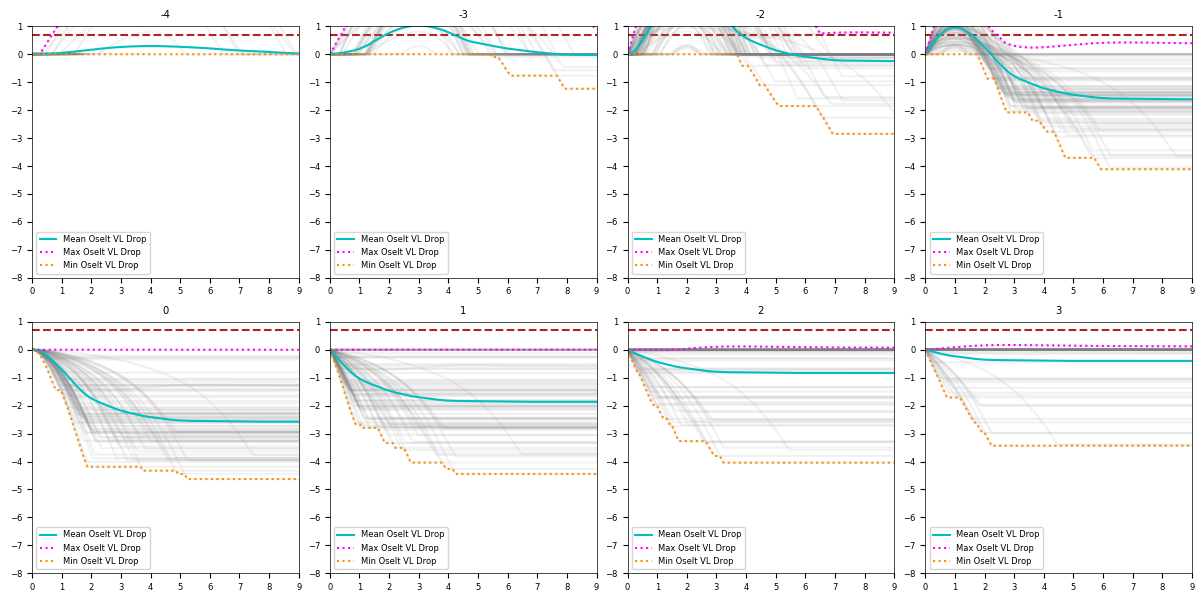

In [178]:
# Aligning the measure of drop from baseline based on peak viral load (of each individual) 
# Establish time vector t
for count,ID in enumerate(IDs[0:1]):
    params_dict = GetParams(parameters_df, ID, style = 'mode') 
    t,y = Simulate(deriv, param_order, params_dict, init, 40, 10000)

dt = t[1]-t[0]                    # delta time
ind_1day = np.round(1/dt)         # frequency of sampling: the number of time steps that equal 1 day 
                                  # (10,0000 points over 40 days = 10000/40 = 250 per day) 

fig, axs = plt.subplots(2,4, figsize = (12,6))
IDs = oselt_placebo_df.ID.unique()

N = len(t)                        # length of time
M = len(IDs)                      # length of volunteers (44), treated (39)


V_untreated = np.zeros((M,N))     # array for simulated values

for count,ID in enumerate(IDs):

    # get parameters function
    params_dict = GetParams(parameters_df, ID, style = 'mode') 

    # Simulate ODE system with individual's parameters
    t,y = Simulate(deriv, param_order, params_dict, init, 40, 10000)

    # maximum vl of individual retrieved from the fifth column; if the original value from y[:,4] is less than initial then convert to inital 10^0.7
    V = np.maximum(y[:,4], 10**0.7)
    
    #plt.plot(t-t_baseline,V,color ='tab:gray', alpha = 0.1, lw = 1)

    # store into matrix 
    V_untreated[count,:] = V

'''
# DOB: days from onset to baseline
# avg_DOB: the number of days relative to peak viral load the baseline measurement is taken (DOB: day of baseline)
# (-4, 4): the range from -4 to 3 days
# -4, -3, -2, -1: Days BEFORE peak viral load (early infection)
# 0: Day at peak viral load
# 1, 2, 3: Days after peak viral load (declining phase) 
'''

for avg_DOB, ax in zip(np.arange(-4,4),fig.axes):
    #ax.plot(Placebo_timepoints,Placebo_Mean,'o-')
    #ax.plot(oselt_timepoints, oselt_Mean,'o-')

    # horizontal line: limit of detection = 0.7 
    ax.hlines(y = 0.7, xmin = 0, xmax = 10, color = 'firebrick',ls = '--')           

    # array to store the drop_untreated difference values
    Drop_untreated = np.zeros((M,N))

    for i in np.arange(0,M):
        # ind_pk: peak of each volunteer 
        ind_pk = np.argmax(V_untreated[i,:])          

        # ind_baseline: individual baseline calculated
        # find the array index corresponding to a specific time point that is the avg day of baseline away from peak viral load
        ind_baseline = int(ind_pk + ind_1day*avg_DOB)     

        # Baseline of individual volunteers
        baseline = V_untreated[i,ind_baseline]

        # Calculating the indivdiual drop: log10(ind drop) - 
        Drop_untreated[i, 0:len(V_untreated[i,ind_baseline:])] = np.log10(V_untreated[i,ind_baseline:])-np.log10(baseline)

        # plot the drop 
        ax.plot(t[0:len(V_untreated[i,ind_baseline:])],
                Drop_untreated[i, 0:len(V_untreated[i,ind_baseline:])],
                '-', color='tab:gray', alpha = 0.1) 
    
    # MEAN drop from baseline of untreated
    ax.plot(t,np.mean(Drop_untreated, axis = 0),'-', color='c', label = "Mean Oselt VL Drop")   

    # MAX drop from baseline of untreated
    ax.plot(t,np.max(Drop_untreated, axis = 0),':', color='fuchsia', label = "Max Oselt VL Drop") 

    # MIN drop from baseline of untreated
    ax.plot(t,np.min(Drop_untreated, axis = 0),':', color='darkorange', label = "Min Oselt VL Drop")  

    ax.legend()
    ax.set_xlim(0,9)
    ax.set_ylim(-8,1)
    ax.set_title(str(avg_DOB))
    
plt.tight_layout()

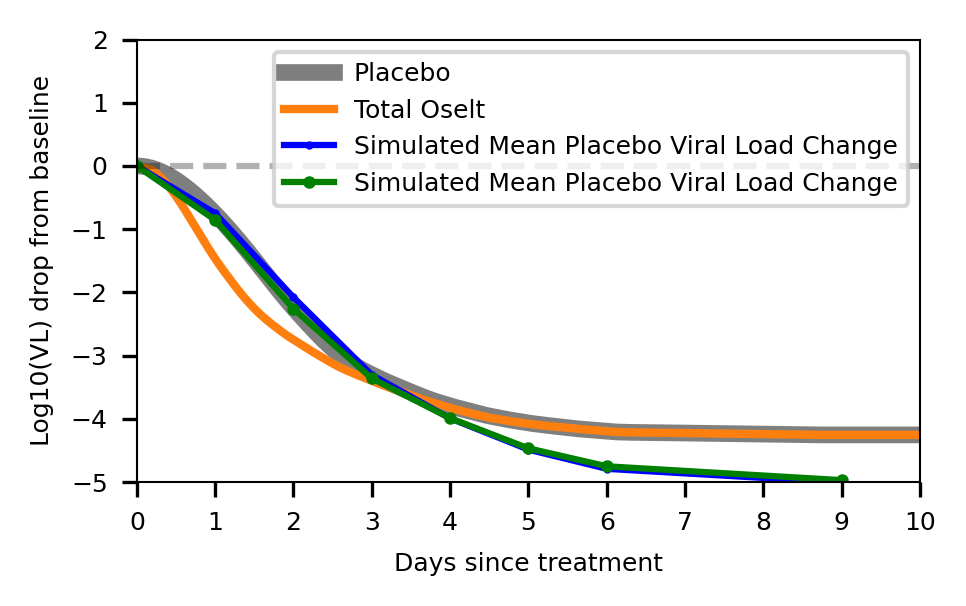

In [212]:
## Plotting the viral load change relative to baseline 

IDs = oselt_placebo_df.ID.unique()

t_baseline = 0                            # time of baseline measurement is at peak viral load
treat_start = 0                           # start treatment immediately following baseline measurement
treat_end_O =  treat_start + 5            # 5 days of oseltamavir

simu_time = np.array([0, 1,2,3,4,5,6,9])        # Day 0 = Day 1 before the initiation of the trial regimen in NEJM paper
# simulated data
simu_placebo_vdparam = np.array([0,
                      # vd model  oselt-treat model estimated param
                       -0.854,         #-0.748,
                       -2.259,          #-2.077,
                       -3.360,          #-3.304,
                       -3.988,          #-3.991,
                       -4.465,          #-4.486146,
                       -4.749,          #-4.789552,
                       -4.968,          #-5.004807
                       ])

#simulated data
simu_placebo_treatparam = np.array([
    0,
    -0.748,
    -2.077,
    -3.304,
    -3.991,
    -4.486146,
    -4.789552,
    -5.00487
])

# another simulated result
simu_placebo3 = np.array([
    0,
    -0.001081,
    -0.002665,
    -0.004354,
    -0.006071,
    -0.007795,
    -0.009521,
    -0.014700
])

# Digitized data
oselt_Mean = np.array([0,
                       -2.5363286824163627,
                       -4.216109085143492,
                       -4.631619628983669,
                       -4.983213096559378,
                       -4.859739178690344,
                       -5.22877358490566
                       ])
        

fig = plt.figure(figsize =(3.2,2), dpi = 300)
plt.rcParams.update({'font.size': 6, 'axes.linewidth':.5})

N = len(t)
M = len(IDs)

#--------------------#
# Arrays to store values
#--------------------#
V_untreated = np.zeros((M,N))
V_O = np.zeros((M,N))
V_OUB = np.zeros((M,N))

# Vector to store baseline values
Baselines = []

for count,ID in enumerate(IDs):
    params_dict = GetParams(parameters_df, ID, style = 'mode')

    #------------------------------#
    # Simulating Placebo: ODE system (Model 4) 
    #------------------------------#
    t,y = Simulate(deriv, param_order, params_dict, init, 40, 10000)
    V = np.log10(np.maximum(y[:,4],0.1))
    V_untreated[count,:] = V
    
    #------------------------------#
    # Determine individual peak viral load 
    #------------------------------#
    pk_ind = np.argmax(V)          # peak viral load
    tpk = t[np.argmax(V)]          # time of peak viral load 
    Baselines.append(pk_ind)       # append to 'Baselines' vector 
    
    # set individual timing
    t_baseline_temp = tpk + t_baseline

    #------------------------------#
    # Plotting 
    ####### Placebo Individual's baseline drop in gray
    #plt.plot(t-t_baseline_temp,V,color ='tab:gray', alpha = 0.1, lw = 1)
    
    treat_start_temp = tpk + treat_start             # start of treatment for placebo at peak viral + '0' days
    treat_end_O_temp = tpk + treat_end_O             # start of treatment for oselt

    #------------------------------#
    # Simulating the treatment system (Model 4 with oselt) -- oselt treated
    #------------------------------#
    # oseltamivir: V0 - oselt, VUB - unbounded
    tt,yt = SimulateTreatment(
                              derivOseltamivir, 
                              param_order_oselt, 
                              params_dict, 
                              initTreatment, 
                              40, 10000,
                              treat_start_temp, 
                              treat_end_O_temp
                             )

    #------------------------------#
    # Oselt all individual's baseline drop in orange
    # Total virus: ttl_V = V + f*Vb
    #------------------------------#
    f = 0.75 
    VO = np.log10(np.maximum(yt[:,5]+ f* yt[:,4],0.1))                                      
    V_O[count,:] = VO
    # plt.plot(t-t_baseline_temp,VO,color ='tab:orange', alpha = 0.1, lw = 1)

    #------------------------------#
    # Oselt unbounded virus: all individual's baseline drop in red
    # DON'T NEED to plot the unbounded virus -- plotting the total viral load 
    #------------------------------# 
    #VUB = np.log10(np.maximum(yt[:,5],0.1))           
    #V_OUB[count,:] = VUB
    #plt.plot(t-t_baseline_temp,VUB,color ='tab:red', alpha = 0.1, lw = 1)

    #------------------------------#
   

#------------------------------#
# Next, we align things by the individual baseline
#------------------------------#
N_tpts = 5250 # 3 weeks (21 days)
V_untreated_alligned = np.zeros((M,N_tpts))
V_O_alligned = np.zeros((M,N_tpts))        #oselt

#---------------------------------------------------#
## Calculating the individual's drop from baselines
#---------------------------------------------------#
for i in np.arange(M):
    baseline_ind = Baselines[i]

    #--------------------#
    # individual baseline values
    #--------------------#
    V0_untreated = V_untreated[i, baseline_ind]                            # initial baseline of placebo
    V0_0 = V_O[i, baseline_ind]                                            # initial baseline of oselt total (calculated)

    #--------------------#
    # Align and subtract baseline
    #--------------------#
    V_untreated_alligned[i,:] = (V_untreated[i, baseline_ind:baseline_ind+N_tpts] - V0_untreated)        # calculate the change at day 1, 2, ...
    V_O_alligned[i,:] = (V_O[i, baseline_ind:baseline_ind+N_tpts] - V0_0)

# ----------------------------------------- #
## Plotting the mean of the treatment arms
# ----------------------------------------- #
plt.plot(np.linspace(0,21,N_tpts),
         np.mean(V_untreated_alligned, axis = 0), 
         color = 'tab:gray', 
         lw = 4, 
         label = 'Placebo')

plt.plot(np.linspace(0,21,N_tpts), 
         np.mean(V_O_alligned, axis = 0), color = 'tab:orange', lw = 2, label = 'Total Oselt')


# overlay the mean calculated vl drop at each day
plt.plot(simu_time,
         simu_placebo_treatparam, 
         marker='o', 
         linestyle='-', 
         color='blue', 
         markersize = 1,
         label = "Simulated Mean Placebo Viral Load Change",
        )

plt.plot(simu_time,
         simu_placebo_vdparam, 
         marker='o', 
         linestyle='-', 
         color='green', 
         markersize = 2,
         label = "Simulated Mean Placebo Viral Load Change",
        )


# ----------------------------------------- #
## Set plot characteristics
# ----------------------------------------- #
plt.xlim(0,10)
plt.ylim(-5, 2)
plt.xticks(np.arange(0,11))
plt.ylabel('Log10(VL) drop from baseline')
plt.xlabel('Days since treatment')   
plt.hlines(y = 0, xmin = 0, xmax = 10,alpha = 0.3, color ='k', ls = '--')
plt.legend(loc = "upper right")          # Display the legend## Time-series plot

plt.tight_layout()


[5.94       3.40367132 1.72389091 1.30838037 0.9567869  1.08026082
 0.71122642]


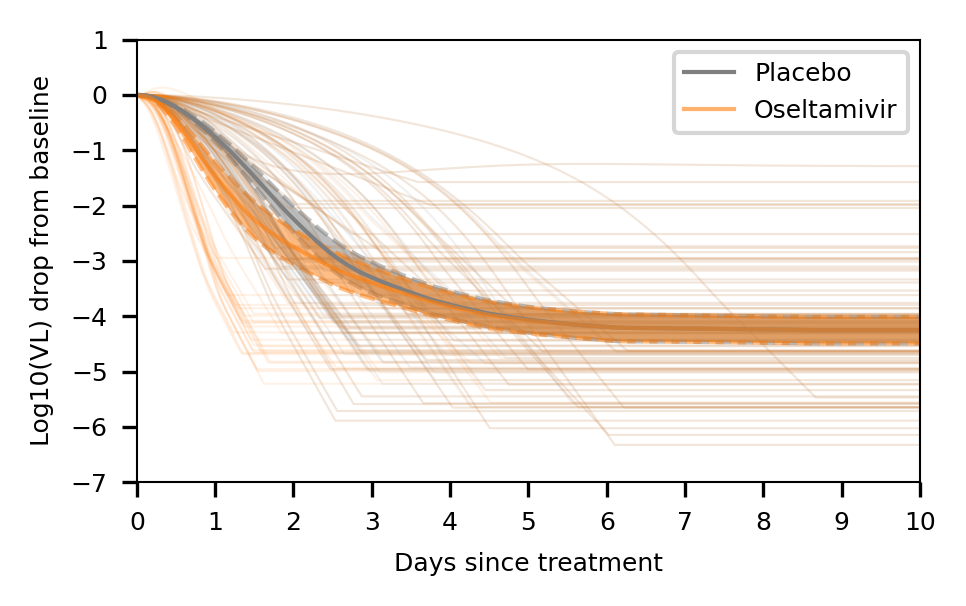

In [204]:
"""
    Plotting time-series plot of placebo and treatment individuals
    Plot individiual's vl drop curves in gray
    Plot mean of each group -  observation mean as markers and model predictions as lines
"""
## Plotting drop from baseline with 95% CI 

DropBaseline_untreated = np.zeros((M,N_tpts))
DropBaseline_O = np.zeros((M,N_tpts))
DropBaseline_OUB = np.zeros((M,N_tpts))

import matplotlib.pyplot as plt

## Digitized Hayden 2018 (NEJM): Treatment - Oseltamivir 
# NEJM (approximated) time points of change from baseline in Phase 3 trial (Figure 3):
#oselt_timepoints = np.array([1,2,3,4,5,6,9])        # Day 0 = Day 1 before the initiation of the trial regimen in NEJM paper
oselt_timepoints = np.array([0,1,2,3,4,5,8])        # Day 0 = Day 1 before the initiation of the trial regimen in NEJM paper

# Digitized data
oselt_Mean = np.array([0,
                       -2.5363286824163627,
                       -4.216109085143492,
                       -4.631619628983669,
                       -4.983213096559378,
                       -4.859739178690344,
                       -5.22877358490566
                       ])


'''
"The mean (±SD) viral loads on day 1 (before the initiation of the trial regimen) 
were 5.79±1.87 log10 50% tissue-culture (TCID50) per milliliter in the baloxavir group,
5.56±1.89 log10 50% tissue-culture infective dose (TCID50) per milliter in the placebo group,
5.94±1.69 log10 TCID50 per milliliter in the oseltamivir group
"
LOD = 0.7 TCID50 

'''
# Revert back to viral load
# Given NEJM data: mean viral load on day 1 (before the initiation of the trial regimen):
Placebo_Baseline = 5.56          # SD: +/- 1.89 
oselt_baseline = 5.94            # SD: +/- 1.69

digitized_oselt_vl = oselt_baseline + oselt_Mean       # digitize and calculated mean oseltamivir viral load

print(digitized_oselt_vl)

# plotting the digitized Hayden data


# Define the data points
x = oselt_timepoints # np.array([0,1,2,3,4,5, 6)
y = oselt_Mean #digitized_oselt_vl #


# ----------------------------------------- #
for count in np.arange(0,M):
    
    # Determine baseline value first
    baseline = V_untreated_alligned[count, 0]

    #### Calculate the differences for each arm
    # Placebo
    DropBaseline_untreated[count, :] = V_untreated_alligned[count, :] - baseline

    # Oseltamivir 
    DropBaseline_O[count, :] = V_O_alligned[count, :] - baseline

# ----------------------------------------- #
fig = plt.figure(figsize =(3.2, 2), dpi = 300)
plt.rcParams.update({'font.size': 6, 'axes.linewidth':.5})

# ----------------------------------------- #
# All Indivdiuals 
# ----------------------------------------- #
plt.plot(np.linspace(0,21,N_tpts), DropBaseline_untreated.T, color = 'tab:gray',alpha = 0.1, lw = .5 );
plt.plot(np.linspace(0,21,N_tpts), DropBaseline_O.T, color = 'tab:orange',alpha = 0.1, lw = .5  );

# ----------------------------------------- #
# Overlay the digitized data from Hayden 2018 NEJM clinical trial results on top of the simulated results
# ----------------------------------------- #
# horizontal line: limit of detection = 0.7 
#plt.hlines(y = 0.007, xmin = 0, xmax = 10, color = 'gray',ls = '--')           

# Create the digitized line (from Hayden 2018 clinical trial)
#plt.plot(x, y, marker ='o', linestyle='-', color = 'tomato', markersize = 2, lw = 1, label = "Digitized Mean Oselt VL Drop" )

# ----------------------------------------- #
# drop from baseline for placebo (gray)
# ----------------------------------------- #
# scatter plot
#plt.scatter(
    #using digitized timepoints from NEJM paper instead of linear space
#    np.linspace(0,21,N_tpts),
#    np.mean(DropBaseline_untreated, axis=0),
#    color='tab:red',
#    s=30,
#    label='Placebo'
#)

# Mean, continuous curve
plt.plot(np.linspace(0,21,N_tpts), 
         np.mean(DropBaseline_untreated, axis = 0), 
         color = 'tab:gray', 
         lw = 1, 
         label = 'Placebo')
interval = 0.95
CI_low = []
CI_high = []

for i in np.arange(0,N_tpts-1):
    filtered_data = DropBaseline_untreated[:,i]
    ans = st.norm.interval(confidence = interval, loc = np.mean(filtered_data), scale=st.sem(filtered_data))
    CI_low.append(ans[0])
    CI_high.append(ans[1]) 

CI_low.append(ans[0])
CI_high.append(ans[1]) 
plt.fill_between(np.linspace(0,21,N_tpts), CI_low, CI_high,color = 'tab:gray',ls = "--", alpha = .5)

# ----------------------------------------- #
# drop from baseline for OSELTAMIVIR (orange)
# ----------------------------------------- #
# Mean, continuous curve
plt.plot(np.linspace(0,21,N_tpts), 
         np.mean(DropBaseline_O, axis = 0), 
         alpha = 0.6,
         color = 'tab:orange', 
         lw = 1, 
         label = 'Oseltamivir')
CI_low = []
CI_high = []

for i in np.arange(0,N_tpts-1):
    filtered_data = DropBaseline_O[:,i]
    ans = st.norm.interval(confidence = interval, loc=np.mean(filtered_data), scale=st.sem(filtered_data))
    CI_low.append(ans[0])
    CI_high.append(ans[1]) 

CI_low.append(ans[0])
CI_high.append(ans[1]) 
plt.fill_between(np.linspace(0,21,N_tpts), CI_low, CI_high,color = 'tab:orange',ls = "--", alpha = .5)

# ----------------------------------------- #
# Set plot properties
# ----------------------------------------- #
#plt.hlines(y = 0, xmin = 0, xmax = 10, alpha = 0.3, ls = '--', color = 'k')      # horizontal line at y = 0
plt.xlim(0,10)
plt.xticks(np.arange(0,11))
plt.yticks(np.arange(-8,2))
plt.ylim(-7, 1)
ax = plt.gca()
ax.spines[['right', 'top']].set_visible(True)
plt.legend()
plt.ylabel('Log10(VL) drop from baseline')
plt.xlabel('Days since treatment')                # original x-label: days from baseline = peak viral load
#plt.xlabel('Days from Peak Viral Titer')
#plt.title('Mean Mechanism of Action Drives Differential Clearance Kinetics', fontsize = 8)

plt.tight_layout()

#plt.savefig('Placebo_Oselt_Simulated.png',bbox_inches='tight', transparent = True)


[5.94       3.40367132 1.72389091 1.30838037 0.9567869  1.08026082
 0.71122642]


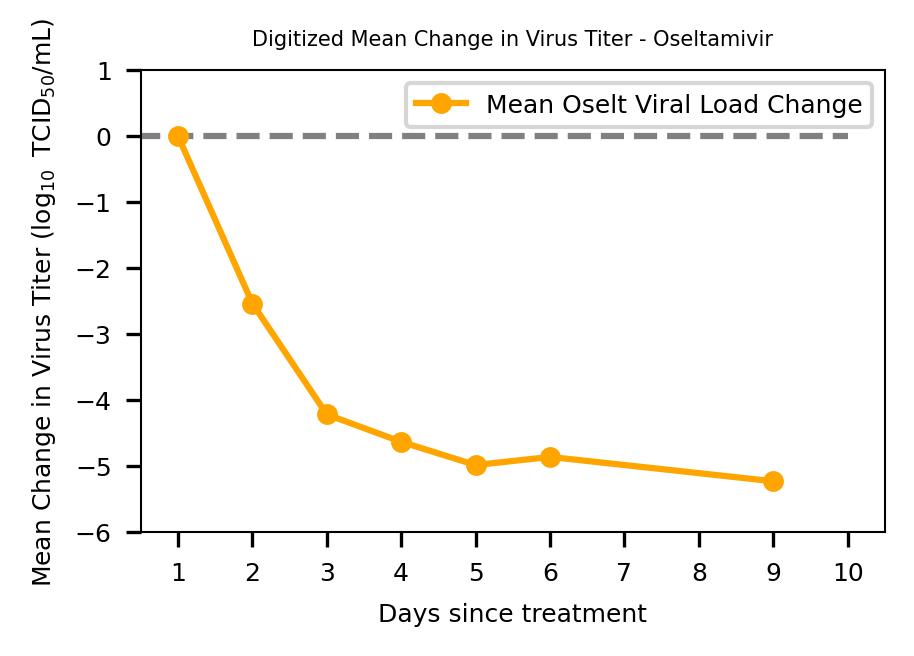

In [213]:
import matplotlib.pyplot as plt

## Digitized Hayden 2018 (NEJM): Treatment - Oseltamivir 
# NEJM (approximated) time points of change from baseline in Phase 3 trial (Figure 3):
oselt_timepoints = np.array([1,2,3,4,5,6,9])        # Day 0 = Day 1 before the initiation of the trial regimen in NEJM paper

# Digitized data
oselt_Mean = np.array([0,
                       -2.5363286824163627,
                       -4.216109085143492,
                       -4.631619628983669,
                       -4.983213096559378,
                       -4.859739178690344,
                       -5.22877358490566
                       ])
        


'''
"The mean (±SD) viral loads on day 1 (before the initiation of the trial regimen) 
were 5.79±1.87 log10 50% tissue-culture (TCID50) per milliliter in the baloxavir group,
5.56±1.89 log10 50% tissue-culture infective dose (TCID50) per milliter in the placebo group,
5.94±1.69 log10 TCID50 per milliliter in the oseltamivir group
"
LOD = 0.7 TCID50 

'''
# Revert back to viral load
# Given NEJM data: mean viral load on day 1 (before the initiation of the trial regimen):
Placebo_Baseline = 5.56          # SD: +/- 1.89 
oselt_baseline = 5.94            # SD: +/- 1.69

digitized_oselt_vl = oselt_baseline + oselt_Mean       # digitize and calculated mean oseltamivir viral load

print(digitized_oselt_vl)

# plotting the digitized Hayden data
# Define the data points
x = oselt_timepoints #np.array([0,1,2,3,4,5, 6)
y = oselt_Mean

digitized_fig = plt.figure(figsize =(3.2, 2), dpi = 300)

# horizontal line: limit of detection = 0.7 
plt.hlines(y = 0.007, xmin = 0, xmax = 10, color = 'gray',ls = '--')           

# Create the line plot
plt.plot(x, y, marker='o', 
         linestyle='-', 
         color='orange', 
         markersize = 4,
         label = "Mean Oselt Viral Load Change",
        )

plt.plot(x, y_sim, marker='o', 
         linestyle='-', 
         color='blue', 
         markersize = 4,
         label = "Simulated Mean Placebo Viral Load Change",
        )

# Tick mark range: Give room at the beginning by setting the axis limit to start at 0
plt.xlim(0.5, 10.5) 
plt.xticks(range(1, 11, 1)) 
plt.ylim(-6, 1)

# Add labels and a title
plt.title("Digitized Mean Change in Virus Titer - Oseltamivir",  fontsize=5)
plt.xlabel("Days since treatment")
plt.ylabel("Mean Change in Virus Titer ($\log_{10}$ TCID$_{50}$/mL)")
plt.legend()

# Display the window
plt.show()


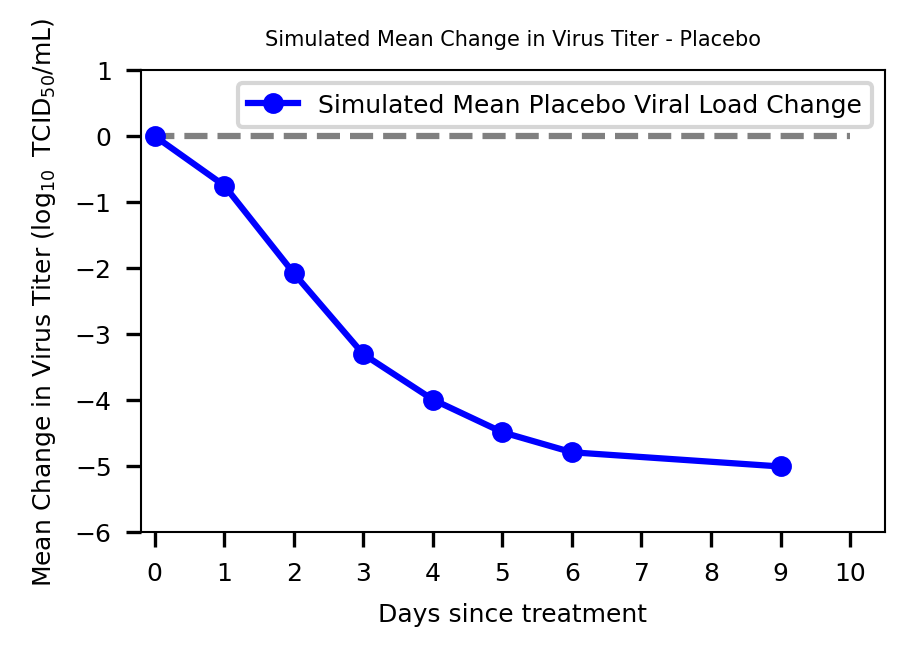

In [206]:
import matplotlib.pyplot as plt

## Digitized Hayden 2018 (NEJM): Treatment - Oseltamivir 
# NEJM (approximated) time points of change from baseline in Phase 3 trial (Figure 3):
oselt_timepoints = np.array([0,1,2,3,4,5,6,9
                            ])        # Day 0 = Day 1 before the initiation of the trial regimen in NEJM paper

# Simulated vl change data
simu_placebo_drop = np.array([0,
                       -0.748,
                       -2.077,
                       -3.304,
                       -3.991,
                       -4.486146,
                       -4.789552,
                       -5.004807
                       ])

# plotting the digitized Hayden data
# Define the data points
x = oselt_timepoints #np.array([0,1,2,3,4,5, 6)
y_sim = simu_placebo_drop #oselt_Mean

digitized_fig = plt.figure(figsize =(3.2, 2), dpi = 300)

# horizontal line: limit of detection = 0.7 
plt.hlines(y = 0.007, xmin = -1, xmax = 10, color = 'gray',ls = '--')           

# Create the line plot
plt.plot(x, y_sim, marker='o', 
         linestyle='-', 
         color='blue', 
         markersize = 4,
         label = "Simulated Mean Placebo Viral Load Change",
        )

# Tick mark range: Give room at the beginning by setting the axis limit to start at 0
plt.xlim(-0.2, 10.5) 
plt.xticks(range(0, 11, 1)) 
plt.ylim(-6, 1)

# Add labels and a title
plt.title("Simulated Mean Change in Virus Titer - Placebo",  fontsize=5)
plt.xlabel("Days since treatment")
plt.ylabel("Mean Change in Virus Titer ($\log_{10}$ TCID$_{50}$/mL)")
plt.legend()

# Display the window
plt.show()
